In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
df=pd.read_csv('/content/Ice_cream selling data (1).csv')
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [ ]:
df.shape

(49, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [ ]:
df.describe()

,Temperature (°C),Ice Cream Sales (units)
count,49.000000,49.000000
mean,0.271755,15.905308
std,2.697672,12.264682
min,-4.662263,0.328626
25%,-2.111870,4.857988
50%,0.688781,12.615181
75%,2.784836,25.142082
max,4.899032,41.842986


In [ ]:
#duplicates
print(df.duplicated().sum())
# Remove duplicates if any
df.drop_duplicates(inplace=True)

0


<Axes: ylabel='Temperature (°C)'>

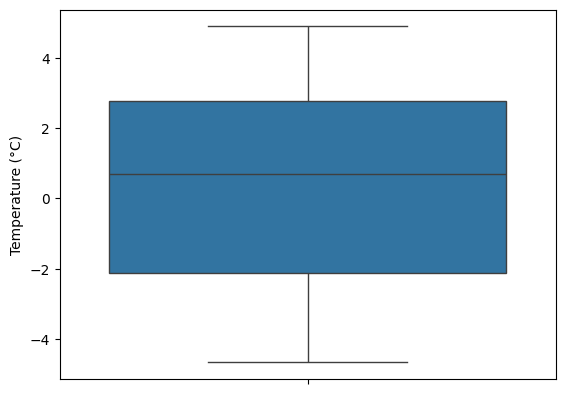

In [ ]:
#Outlier detection
sns.boxplot(df['Temperature (°C)'])

In [ ]:
#dependent&independent variable
x=df['Temperature (°C)'] #df.iloc[:,0].values
y=df['Ice Cream Sales (units)'] #df.iloc[:,1].values

Text(0, 0.5, 'Ice Cream Sales (units)')

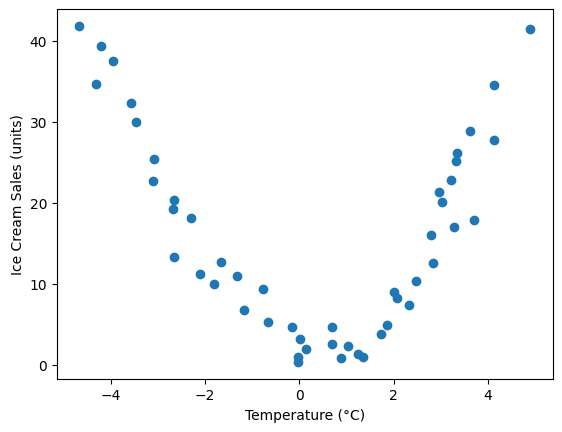

In [ ]:
#rln b/w dependent&non-dependent is Linear/non-linear
plt.scatter(x,y)
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')

In [ ]:
# Split the dataset into training and testing sets
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
model=LinearRegression()
model.fit(x_train.values.reshape(-1,1),y_train)

LinearRegression()

In [ ]:
print(f"Number of instances for training: {len(x_train)}")
print(f"Number of instances for testing: {len(x_test)}")

Number of instances for training: 39
Number of instances for testing: 10


In [ ]:
polynomial_features=PolynomialFeatures(degree=2)

In [ ]:
x_poly=polynomial_features.fit_transform(x.to_frame())

In [ ]:
#Model Building
lr_model=LinearRegression()
lr_model.fit(x_poly,y)

LinearRegression()

In [ ]:
#Model Training
x_train_poly = polynomial_features.transform(x_train.to_frame())
model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
#Predictions
y_pred=lr_model.predict(x_poly)
df=pd.DataFrame({'Actual':y,'Predicted':y_pred})
print(df)

       Actual  Predicted
0   41.842986  46.564507
1   34.661120  40.600548
2   39.383001  38.915089
3   37.539845  34.749272
4   32.284531  29.331940
5   30.001138  27.649735
6   22.635401  23.192862
7   25.365022  22.863178
8   19.226970  18.222266
9   20.279679  18.009098
10  13.275828  18.000794
11  18.123991  14.418541
12  11.218294  12.853070
13  10.012868  10.504868
14  12.615181   9.364587
15  10.957731   7.264266
16   6.689123   6.437055
17   9.392969   4.683654
18   5.210163   4.337906
19   4.673643   3.116139
20   0.328626   2.983983
21   0.897603   2.981829
22   3.165600   2.944811
23   1.931416   2.869446
24   2.576782   3.251711
25   4.625689   3.259923
26   0.789974   3.630683
27   2.313806   4.026226
28   1.292361   4.744891
29   0.953115   5.213321
30   3.782570   7.055902
31   4.857988   7.690948
32   8.943823   8.616039
33   8.170735   9.118494
34   7.412094  10.874961
35  10.336631  12.092557
36  15.996620  14.843721
37  12.568237  15.287199
38  21.342916  16.539614


In [ ]:
#Evaluation metrics on training dataset
print("Model Evaluation Metrics on Training Dataset:")
y_train_pred = model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("  Mean Absolute Error (MAE):", mae)
print("  Mean Squared Error (MSE):", mse)
print("  Root MSE (RMSE):", rmse)
print("  R2 Score:", r2)

Model Evaluation Metrics on Training Dataset:
  Mean Absolute Error (MAE): 2.6212779230395755
  Mean Squared Error (MSE): 9.550879189587246
  Root MSE (RMSE): 3.0904496743333723
  R2 Score: 0.9384567189055858


In [ ]:
#Evaluation metrics on testing dataset
print("Model Evaluation Metrics on Testing Dataset:")
x_test_poly = polynomial_features.transform(x_test.to_frame())
y_test_pred = model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("  Mean Absolute Error (MAE):", mae)
print("  Mean Squared Error (MSE):", mse)
print("  Root MSE (RMSE):", rmse)
print("  R2 Score: ", r2)

Model Evaluation Metrics on Testing Dataset:
  Mean Absolute Error (MAE): 3.3963290524224634
  Mean Squared Error (MSE): 13.086802211382846
  Root MSE (RMSE): 3.6175685496453065
  R2 Score:  0.8751729819534021


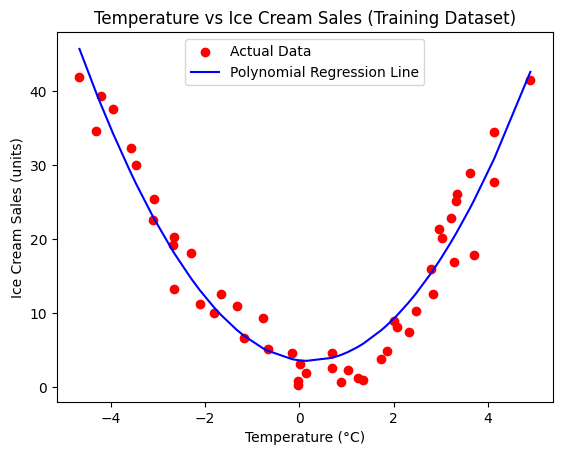

In [ ]:
plt.scatter(x,y,color='red',label='Actual Data')
plt.plot(x,model.predict(polynomial_features.transform(x.to_frame())),color='blue',label='Polynomial Regression Line')
plt.legend()
plt.title('Temperature vs Ice Cream Sales (Training Dataset)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')
plt.show()